In [60]:
import torch
import torchao
from torch import nn

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt

import torchvision
import torch.nn.functional as F
from torch.optim.lr_scheduler import ExponentialLR


import gc
from collections import defaultdict
import typing as tp
import numpy as np
from scipy.optimize import linprog
import copy
import pickle
from math import sqrt
from copy import deepcopy
from typing import Dict, Iterable, Optional, Union, Any, Callable, Tuple


In [61]:
DATASET_FOLDER = '~/projects/datasets'


train_transformations = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.RandomRotation((-7,7)),
    torchvision.transforms.RandomAffine(0, shear=10, scale=(0.8,1.2)),
    torchvision.transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize((0.491, 0.482, 0.446), (0.247, 0.243, 0.261))
])

test_transformations = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize((0.491, 0.482, 0.446), (0.247, 0.243, 0.261))
])


cifar_train = torchvision.datasets.CIFAR10(root=DATASET_FOLDER,
                                           transform=train_transformations,
                                           download=True,
                                           train=True)


cifar_test = torchvision.datasets.CIFAR10(root=DATASET_FOLDER,
                                          transform=test_transformations,
                                          download=True,
                                          train=False)


In [62]:
class Resnet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torchvision.models.resnet34()
        self.net.fc = nn.Linear(512, 10)

    def forward(self, x):
        return self.net(x)

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output


def calc_envelope_line(X, Y):
    n = len(X)
    c = np.array([0.0, 0.0, 1.0])

    A_ub = np.zeros((2 * n, 3))
    b_ub = np.zeros(2 * n)

    for i in range(n):
        A_ub[i, 0] = -X[i]
        A_ub[i, 1] = -1.0
        A_ub[i, 2] = 0.0
        b_ub[i] = -Y[i]

        A_ub[n + i, 0] = X[i]
        A_ub[n + i, 1] = 1.0
        A_ub[n + i, 2] = -1.0
        b_ub[n + i] = Y[i]

    bounds = [(None, None), (None, None), (0, None)]  # t >= 0

    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs', options=dict(maxiter=1000))
    m, b_opt, t_opt = res.x
    return m, b_opt

def plot_loss(values):
    clear_output()
    with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
        plt.figure(figsize=(24, 6), dpi=150)

        # plt.suptitle(f"{title_prefix}, batch size {batch_size}, learning rate {lr:.4f}")

        # plt.subplot(1, 5, 1)
        plt.subplot(1, 3, 1)
        vals = values["train_loss"]
        plt.plot(range(1, len(vals) + 1), vals)
        plt.title('Train loss')
        plt.xlabel("Iterations")

        # plt.subplot(1, 5, 2)
        plt.subplot(1, 3, 2)
        vals = values["test_accuracy"]
        plt.plot(range(1, len(vals) + 1), vals)
        plt.title('Test accuracy')
        plt.xlabel("Epochs")

        grad_diff = np.array(values["grad_diff"])
        coeff_diff = np.array(values["coeffs_diff"])
        grad_norm = np.array(values["grad_norm"][:-1])

        # plt.subplot(1, 5, 3)  
        # plt.plot(range(1, len(grad_diff) + 1), grad_diff / coeff_diff)
        # plt.title('Smoothness')
        # plt.xlabel("Iterations")

        # plt.subplot(1, 5, 4)
        # plt.plot(range(1, len(grad_norm) + 1), grad_norm)
        # plt.title('Gradient norm')
        # plt.xlabel("Iterations")

        plt.subplot(1, 3, 3)
        # plt.subplot(1, 5, 5)
        smoothness = grad_diff / coeff_diff
        iterations = range(1, len(grad_diff) + 1)

        L_1, L_0 = calc_envelope_line(grad_norm, smoothness)
        # L_1 = 0.1
        # L_0 = 21

        sc = plt.scatter(
            grad_norm,
            smoothness,
            c=iterations,
            cmap='viridis',
            alpha=0.7,
            edgecolor='k',
            linewidth=0.3
        )

        plt.text(
            5., 2.,
            s=rf'$L_0$={L_0:.1f}, $L_1$={L_1:.1f}',
            fontsize=12, color='blue',
            # ha='right', va='bottom',
        )

        x_line = np.linspace(grad_norm.min(), grad_norm.max(), 1000)
        plt.plot(x_line, L_1 * x_line + L_0, color='blue')

        cbar = plt.colorbar(sc, label='Iteration')
        plt.xlabel('Gradient norm')
        plt.ylabel('Smoothness')
        plt.title('Smmothness per iterations')
        plt.grid(True, linestyle='--', alpha=0.5)

        plt.show()


In [64]:
def get_list_grad_params(net: nn.Module) -> tp.List[torch.Tensor]:
    return [param.grad.detach().cpu() for param in net.parameters() if param.grad is not None]

def get_list_coeffs(net: nn.Module) -> tp.List[torch.Tensor]:
    return [param.detach().cpu() for param in net.state_dict().values()]

def calc_grad_info(net: nn.Module, info: tp.List[torch.Tensor]):
    new_grads = get_list_grad_params(net)
    if not info:
        return new_grads
    return [new_grad + cur_grad for new_grad, cur_grad in zip(new_grads, info)]

def get_dif(grad_info_1: tp.List[torch.Tensor], grad_info_2: tp.List[torch.Tensor]) -> tp.List[torch.Tensor]:
    return [grad_1 - grad_2 for grad_1, grad_2 in zip(grad_info_1, grad_info_2)]

def mult_grad(info: tp.List[torch.Tensor], mult: float):
    return [grad * mult for grad in info] 

def get_grad_norm(grads: tp.List[torch.Tensor]):
    # print(grads)
    return np.sqrt(sum(grad.type(torch.float).norm().item() ** 2 for grad in grads))


In [69]:
def train_cycle(
    model,
    optim,
    scheduler,
    criterion,
    epochs,
    device,
    train_dataloader,
    test_dataloader,
    verbose=True,
):
    history = defaultdict(list)

    previous_grad = None
    previous_coeffs = None

    for _ in range(epochs):
        model.train()

        full_grad = []

        for x, y in tqdm(train_dataloader):
            optim.zero_grad()
            x = x.to(device).type(torch.float)
            logits = model(x)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()

            optim.step()
            
            cur_coeffs = get_list_coeffs(model)            
            cur_grad = get_list_grad_params(model)
            
            # if previous_x:
            #     logits = model(previous_x)
            #     y_ = previous_y.to(device)
            #     prev_loss_batch = criterion(logits, y_)
            #     prev_loss_batch.backward()
            #     prev_grad = get_list_grad_params(model)
            #     history["grad_diff"].append(get_grad_norm(get_dif(cur_grad, previous_grad)))

            if previous_grad:
                history["grad_diff"].append(get_grad_norm(get_dif(cur_grad, previous_grad)))

            if previous_coeffs:
                history["coeffs_diff"].append(get_grad_norm(get_dif(cur_coeffs, previous_coeffs)))

            history["grad_norm"].append(get_grad_norm(cur_grad))

            previous_grad, previous_coeffs = cur_grad, cur_coeffs

            loss_ = loss_batch.detach().item()
            history["train_loss"].append(loss_)
            del x
            del y
            if 'cuda' in device:
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
                gc.collect()

        scheduler.step()

        model.eval()
        with torch.no_grad():
            accuracy = 0
            total = 0
            for x, y in tqdm(test_dataloader):
                data, target = x.to(device).type(torch.float), y
                output = model(data)
                pred = output.argmax(dim=1, keepdim=True).T[0].cpu()
                accuracy += pred.eq(target.view_as(pred)).sum().item()
                total += len(data)
            history["test_accuracy"].append(accuracy / total)

        if verbose:
            plot_loss(history)

    return model, history

In [70]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

batch_size: int = 512
workers: int = 12
learning_rate = 1e-3

suptitle = 'ResNet-34 CIFAR10, Generalized smoothness estimation'


In [71]:

dataloader_train = torch.utils.data.DataLoader(cifar_train,
                                               num_workers=workers,
                                               batch_size=batch_size,
                                               sampler=torch.utils.data.RandomSampler(cifar_train))

dataloader_test = torch.utils.data.DataLoader(cifar_test,
                                              num_workers=workers,
                                              batch_size=batch_size,
                                              sampler=torch.utils.data.RandomSampler(cifar_test))


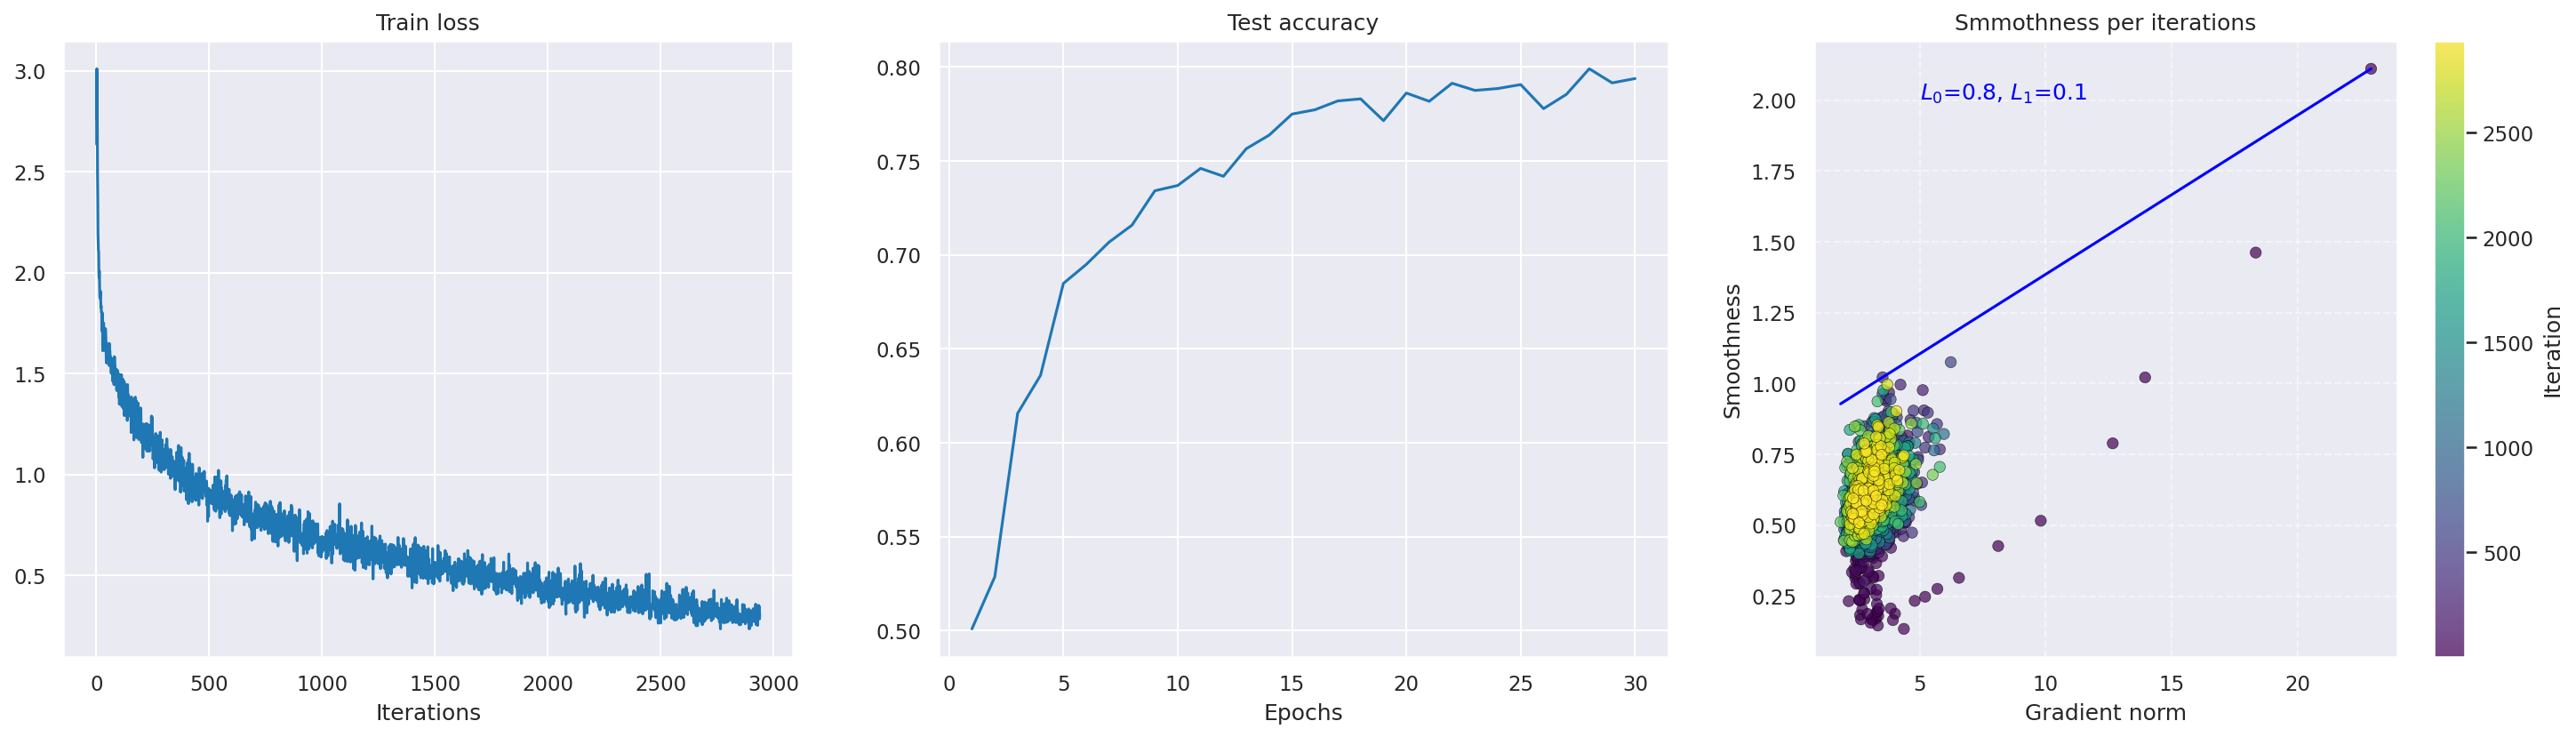

In [72]:
model = Resnet().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = ExponentialLR(optimizer, gamma=0.95)
criterion = nn.CrossEntropyLoss()
verbose = True

epochs = 30

model, history = train_cycle(model,
                             optimizer,
                             scheduler,
                             criterion,
                             epochs,
                             device,
                             dataloader_train,
                             dataloader_test,
                             verbose=True)

In [73]:
with open('./dump_result/resnet34_smoothness.pickle', 'wb') as f:
    pickle.dump(history, f)
